In [1]:
import json
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from jaxley_ephys.events import detect_events, compute_dvdt

In [2]:
from tests.utils.simulate_testdata import simulate_sweep, simulate_sweepset

In [40]:
t, v, i = simulate_sweep()
t0 = jnp.asarray(0.02)
t1 = jnp.asarray(0.1)

In [41]:
detect_events_jitted = jax.jit(lambda tt, vv, ii: detect_events(tt, vv, ii, t0, t1, max_spikes=16))
ev = detect_events_jitted(t, v, i)

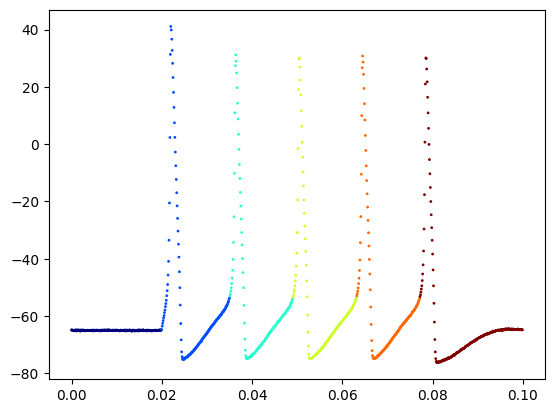

In [42]:
spike_ids = np.asarray(ev.spikes)
n_spikes = int(spike_ids.max())
cmap = plt.get_cmap("jet", n_spikes + 2)  # +2 to include -1 and all spike ids

colors = cmap((spike_ids + 1) / (n_spikes + 1))  # shift so -1 -> 0
plt.scatter(np.asarray(t), np.asarray(v), color=colors, s=1)

In [3]:
t_batch, v_batch, i_batch = simulate_sweepset(
    num_sweeps=5,
    dt=1e-4,
    t_max=0.12,
)
t0 = jnp.full((t_batch.shape[0],), 0.02)
t1 = jnp.full((t_batch.shape[0],), 0.1)


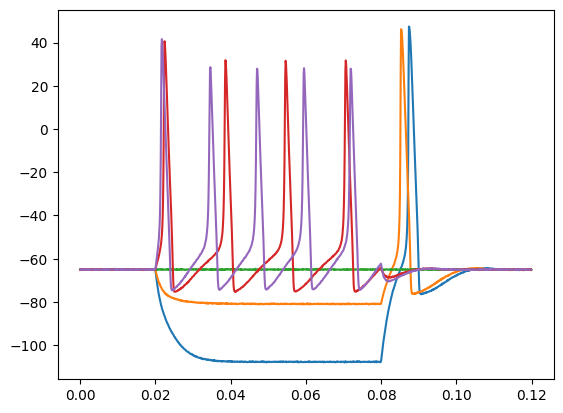

In [4]:
plt.plot(t_batch.T, v_batch.T)

In [47]:
evset = jax.vmap(detect_events_jitted)(t_batch, v_batch, i_batch)

ValueError: detect_events expects scalar array t0 and t1

In [ ]:
# todo: in detect events make t0 and t1 arrays
# todo allow to deal with time-series that have different lengths, by padding